In [ ]:
import pandas as pd

# Read results
default_setting_rows = pd.read_csv("Results/Best settings ASD/default_settings_top5_rows.csv")
max_asd_rows = pd.read_csv("Results/Best settings ASD/max_ASD_top5_rows.csv")

# Read measure results
measure_results = pd.read_csv("../result_measure_run1.csv")
# print mean_pop_diversity of row where full_experiment
default_ids = default_setting_rows["full_experiment"].unique()
pop_diversity_ids = max_asd_rows["full_experiment"].unique()

print(measure_results.loc[measure_results["full_experiment"].isin(default_ids), "mean_pop_diversity"])
print(measure_results.loc[measure_results["full_experiment"].isin(pop_diversity_ids), "mean_pop_diversity"])

107    0.627886
108    0.522729
123    0.517977
124    0.458702
125    0.470880
Name: mean_pop_diversity, dtype: float64
19     1.780266
93     1.555777
113    1.392886
135    0.988155
137    1.573996
Name: mean_pop_diversity, dtype: float64


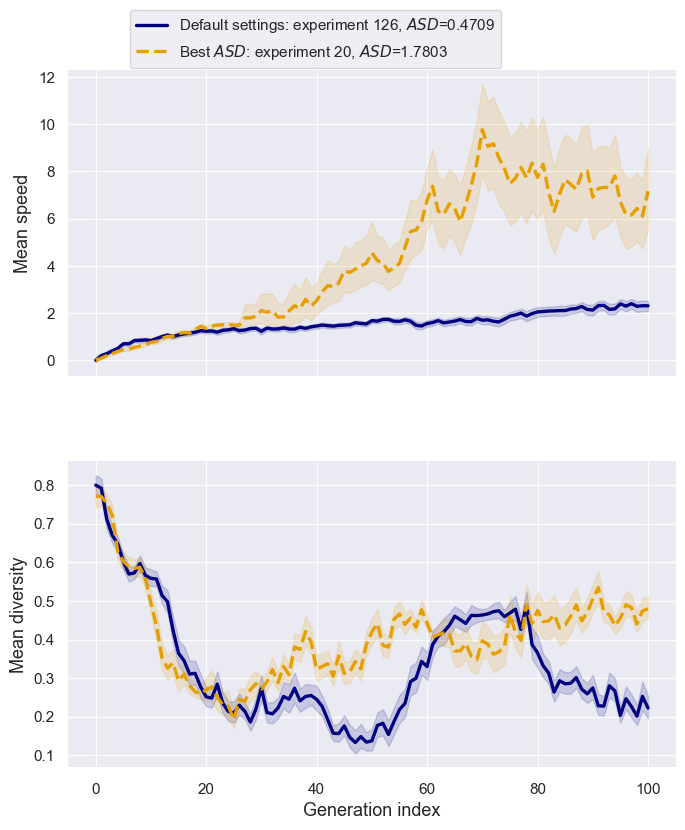

In [4]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(
    style="darkgrid",
    rc={"axes.facecolor": "#EAEAF2", "grid.color": "white"},
)


def bootstrap_generation_summary(data, column, statistic, n_bootstrap=2000, seed=42):
    rng = np.random.default_rng(seed)
    summaries = []

    for generation, group in data.groupby("generation_index"):
        values = group[column].dropna().to_numpy(dtype=float)
        if values.size == 0:
            continue

        if statistic == "max":
            estimate = values.max()
            bootstrap_values = rng.choice(
                values, size=(n_bootstrap, values.size), replace=True
            ).max(axis=1)
        else:
            estimate = values.mean()
            bootstrap_values = rng.choice(
                values, size=(n_bootstrap, values.size), replace=True
            ).mean(axis=1)

        lower, upper = np.quantile(bootstrap_values, [0.025, 0.975])
        summaries.append((generation, estimate, lower, upper))

    return pd.DataFrame(
        summaries, columns=["generation_index", "estimate", "lower", "upper"]
    )


best_default_experiment = (
    default_setting_rows[["full_experiment", "setting_rank"]]
    .drop_duplicates("full_experiment")
    .sort_values("setting_rank")
    .iloc[0]["full_experiment"]
)
best_asd_experiment = (
    max_asd_rows[["full_experiment", "asd_rank"]]
    .drop_duplicates("full_experiment")
    .sort_values("asd_rank")
    .iloc[0]["full_experiment"]
)
mean_diversity_by_experiment = (
    measure_results.drop_duplicates("full_experiment")
    .set_index("full_experiment")["mean_pop_diversity"]
)

solutions = [
    (
        f"Default settings: experiment {best_default_experiment:g}, "
        f"$\\mathit{{ASD}}$={mean_diversity_by_experiment.loc[best_default_experiment]:.4f}",
        default_setting_rows.loc[
            default_setting_rows["full_experiment"] == best_default_experiment
        ],
        "#000080",
        "-",
    ),
    (
        f"Best $\\mathit{{ASD}}$: experiment {best_asd_experiment:g}, "
        f"$\\mathit{{ASD}}$={mean_diversity_by_experiment.loc[best_asd_experiment]:.4f}",
        max_asd_rows.loc[max_asd_rows["full_experiment"] == best_asd_experiment],
        "#E69F00",
        "--",
    ),
]

fig, axes = plt.subplots(2, 1, figsize=(7.5, 8.5), sharex=True)
fig.patch.set_facecolor("white")
plot_specs = [
    ("speed_y", "mean", "Mean speed"),
    ("pop_diversity", "mean", "Mean diversity"),
]

for axis, (column, statistic, y_label) in zip(axes, plot_specs):
    for label, solution_rows, color, line_style in solutions:
        summary = bootstrap_generation_summary(
            solution_rows, column, statistic=statistic, seed=42
        )
        axis.plot(
            summary["generation_index"], summary["estimate"],
            color=color, linestyle=line_style,
            linewidth=2.4, markevery=max(1, len(summary) // 10), markersize=5,
            label=label,
        )
        axis.fill_between(
            summary["generation_index"], summary["lower"], summary["upper"],
            color=color, alpha=0.15,
        )

    axis.set_ylabel(y_label, fontsize=13)
    axis.tick_params(axis="both", labelsize=11)
    axis.grid(True, color="white", alpha=0.9, linewidth=0.8)
    for spine in axis.spines.values():
        spine.set_visible(False)

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(
    handles, labels, loc="upper center", bbox_to_anchor=(0.5, 0.99),
    fontsize=11, frameon=True,
)
axes[-1].set_xlabel("Generation index", fontsize=13)
axes[-1].tick_params(axis="x", labelsize=11, pad=5)
fig.subplots_adjust(left=0.17, right=0.98, bottom=0.09, top=0.91, hspace=0.28)
fig.savefig("best_default_vs_best_asd.png", dpi=300, bbox_inches="tight", pad_inches=0.02)
fig.savefig("best_default_vs_best_asd.pdf", bbox_inches="tight", pad_inches=0.02)
plt.show()

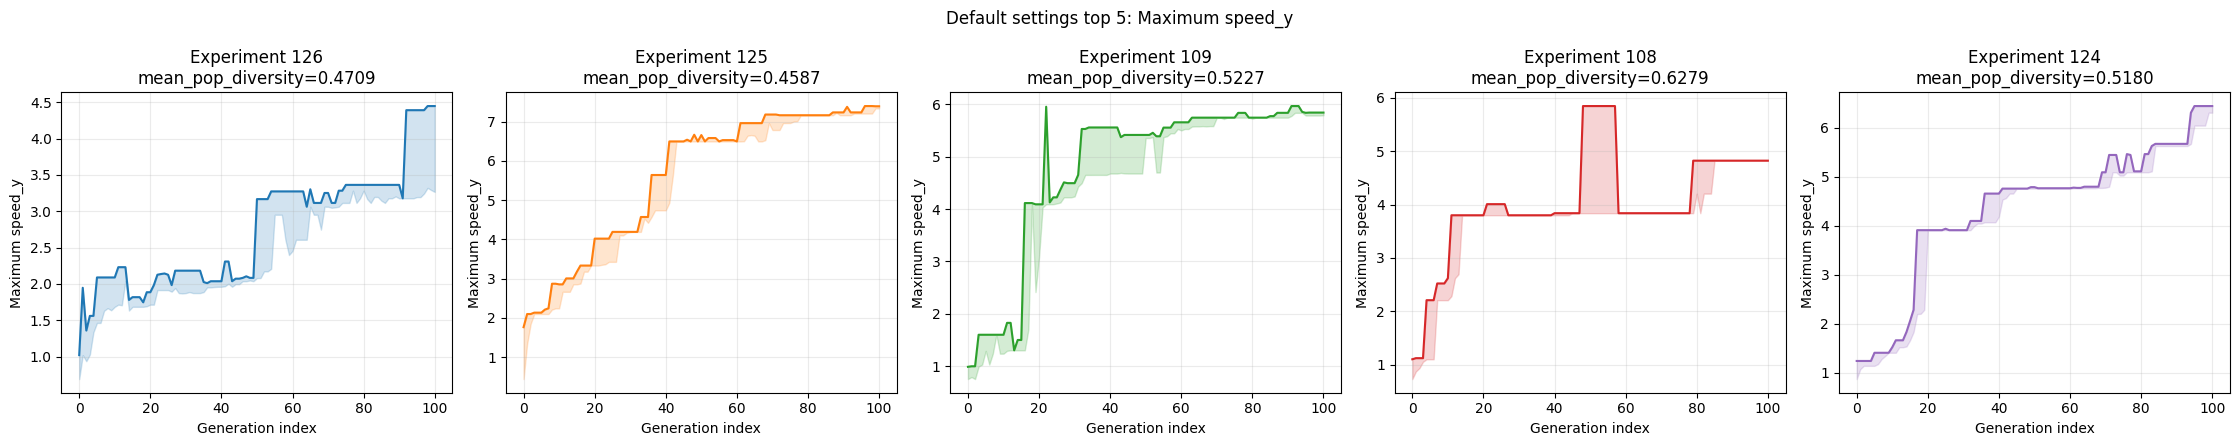

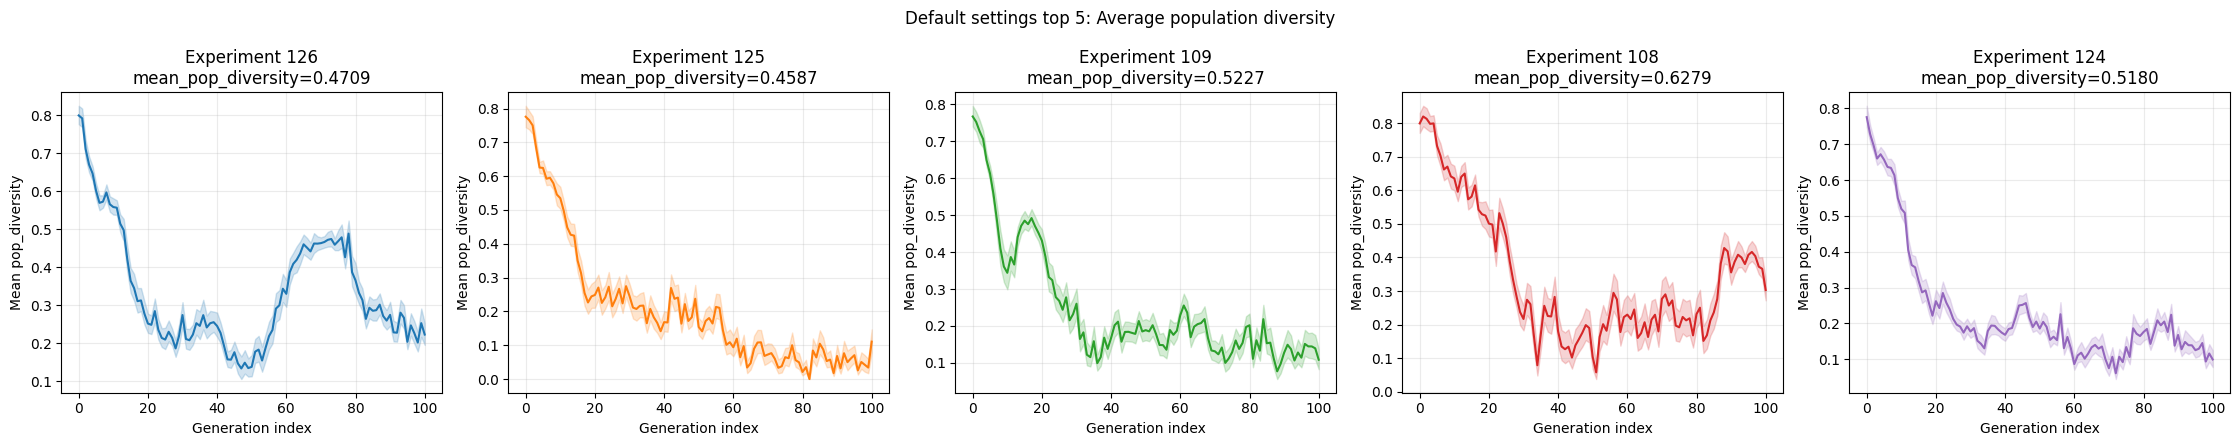

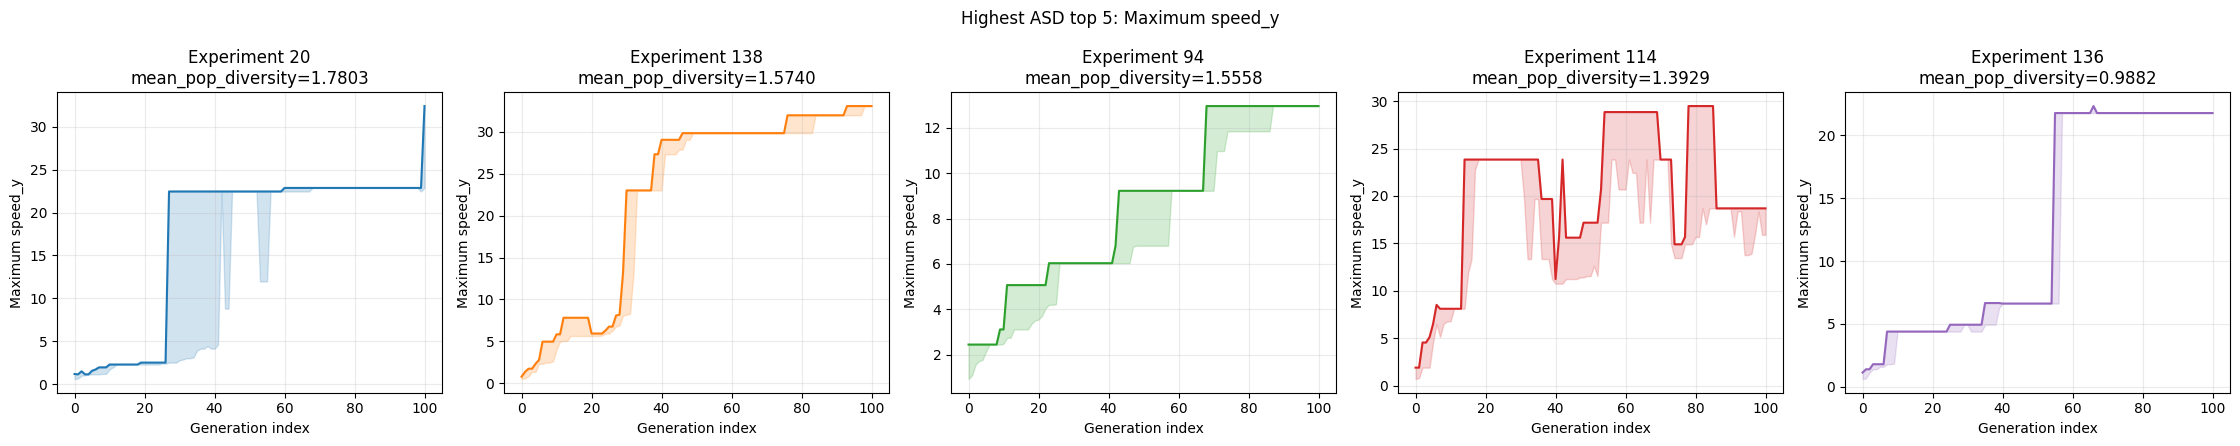

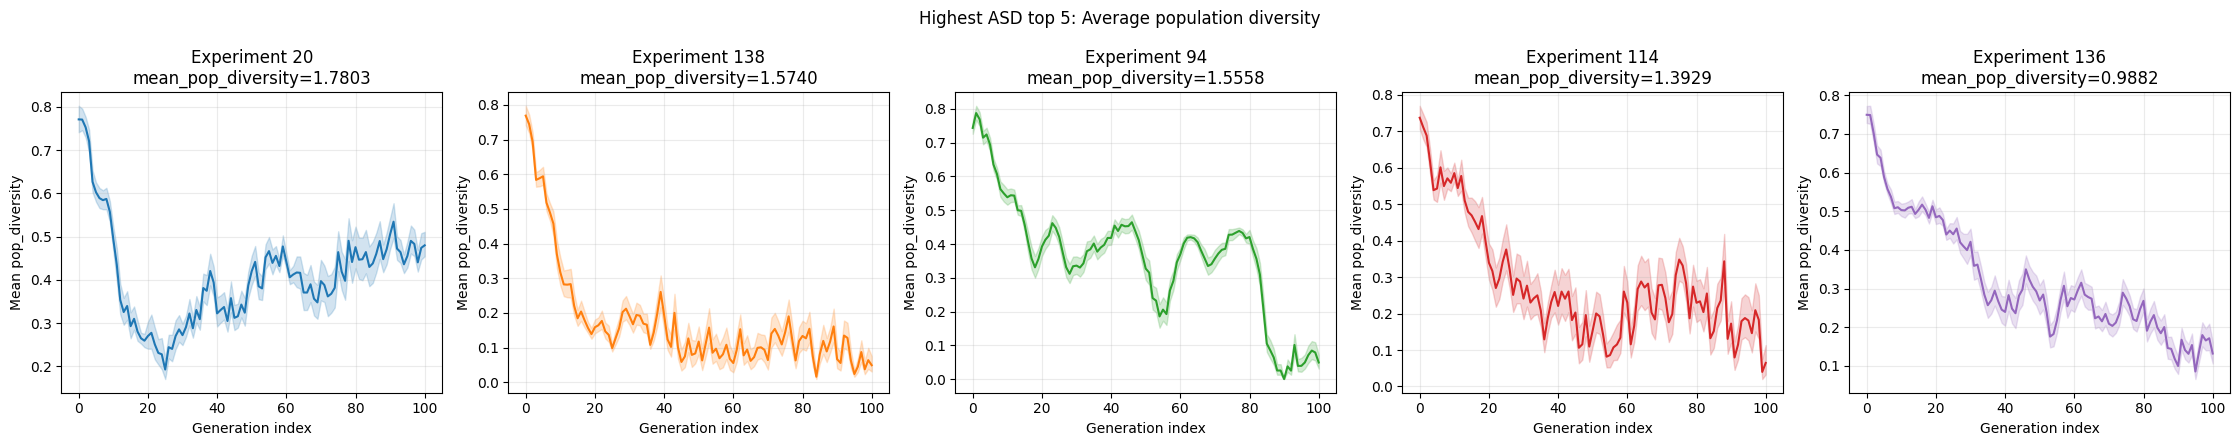

In [25]:
import matplotlib.pyplot as plt

# Load the top-five experiment rows and their overall diversity scores.
default_setting_rows = pd.read_csv("default_settings_top5_rows.csv")
max_asd_rows = pd.read_csv("max_ASD_top5_rows.csv")
measure_results = pd.read_csv("../result_measure_run1.csv")
mean_diversity_by_experiment = (
    measure_results.drop_duplicates("full_experiment")
    .set_index("full_experiment")["mean_pop_diversity"]
)
for data in (default_setting_rows, max_asd_rows):
    data["mean_pop_diversity"] = data["full_experiment"].map(
        mean_diversity_by_experiment
    )


def plot_top5_experiments(data, dataset_name):
    plot_specs = [
        ("speed_y", "max", "Maximum speed_y", "Maximum speed_y"),
        ("pop_diversity", "mean", "Average population diversity", "Mean pop_diversity"),
    ]
    colors = plt.get_cmap("tab10").colors
    experiments = list(data.groupby("full_experiment", sort=False))

    for column, statistic, plot_title, y_label in plot_specs:
        fig, axes = plt.subplots(
            1, len(experiments), figsize=(4.5 * len(experiments), 4.5),
            squeeze=False, sharex=True
        )

        for index, (experiment_id, experiment_rows) in enumerate(experiments):
            summary = bootstrap_generation_summary(
                experiment_rows, column, statistic=statistic, seed=42
            )
            mean_asd = experiment_rows["mean_pop_diversity"].dropna().iloc[0]
            axis = axes[0, index]
            color = colors[index % len(colors)]
            axis.plot(
                summary["generation_index"], summary["estimate"], color=color
            )
            axis.fill_between(
                summary["generation_index"], summary["lower"], summary["upper"],
                color=color, alpha=0.2
            )
            axis.set_title(
                f"Experiment {experiment_id:g}\nmean_pop_diversity={mean_asd:.4f}"
            )
            axis.set_xlabel("Generation index")
            axis.set_ylabel(y_label)
            axis.grid(alpha=0.25)

        fig.suptitle(f"{dataset_name}: {plot_title}")
        fig.tight_layout()
        plt.show()


plot_top5_experiments(default_setting_rows, "Default settings top 5")
plot_top5_experiments(max_asd_rows, "Highest ASD top 5")

In [32]:
def calculate_asd_by_generation(data):
    valid_rows = data.dropna(
        subset=["generation_index", "speed_y", "pop_diversity"]
    )
    generation_stats = valid_rows.groupby("generation_index").agg(
        n=("speed_y", "size"),
        sum_speed=("speed_y", "sum"),
        sum_diversity=("pop_diversity", "sum"),
    )
    generation_stats["mean_speed"] = generation_stats["sum_speed"] / generation_stats["n"]
    generation_stats["sd_j"] = (
        generation_stats["mean_speed"] * generation_stats["sum_diversity"]
    )
    return generation_stats


best_default_experiment = (
    default_setting_rows[["full_experiment", "setting_rank"]]
    .drop_duplicates("full_experiment")
    .sort_values("setting_rank")
    .iloc[0]["full_experiment"]
)
best_asd_experiment = (
    max_asd_rows[["full_experiment", "asd_rank"]]
    .drop_duplicates("full_experiment")
    .sort_values("asd_rank")
    .iloc[0]["full_experiment"]
)

selected_experiments = [
    (
        "Default settings",
        best_default_experiment,
        default_setting_rows.loc[
            default_setting_rows["full_experiment"] == best_default_experiment
        ],
    ),
    (
        "Best ASD",
        best_asd_experiment,
        max_asd_rows.loc[max_asd_rows["full_experiment"] == best_asd_experiment],
    ),
]

summary_rows = []
generation_details = []
for label, experiment_id, experiment_data in selected_experiments:
    generation_stats = calculate_asd_by_generation(experiment_data)
    calculated_asd = generation_stats["sd_j"].mean()
    stored_asd = measure_results.loc[
        measure_results["full_experiment"] == experiment_id,
        "mean_pop_diversity",
    ].iloc[0]

    summary_rows.append(
        {
            "solution": label,
            "full_experiment": experiment_id,
            "generations": len(generation_stats),
            "ASD_calculated": calculated_asd,
            "ASD_in_measure_results": stored_asd,
            "difference": calculated_asd - stored_asd,
        }
    )
    generation_stats = generation_stats.reset_index()
    generation_stats.insert(0, "solution", label)
    generation_stats.insert(1, "full_experiment", experiment_id)
    generation_details.append(generation_stats)

asd_summary = pd.DataFrame(summary_rows)
asd_generation_details = pd.concat(generation_details, ignore_index=True)

display(asd_summary)
display(asd_generation_details)

,solution,full_experiment,generations,ASD_calculated,ASD_in_measure_results,difference
0,Default settings,126.0,101,43.320947,0.470880,42.850068
1,Best ASD,20.0,101,153.023155,1.780266,151.242889


,solution,full_experiment,generation_index,n,sum_speed,sum_diversity,mean_speed,sd_j
0,Default settings,126.0,0.0,92,0.431097,73.567222,0.004686,0.344724
1,Default settings,126.0,1.0,92,18.599046,72.876032,0.202164,14.732877
2,Default settings,126.0,2.0,92,26.201606,65.415196,0.284800,18.630252
3,Default settings,126.0,3.0,92,37.400160,61.625562,0.406523,25.052238
4,Default settings,126.0,4.0,92,46.679868,59.518217,0.507390,30.198941
...,...,...,...,...,...,...,...,...
197,Best ASD,20.0,96.0,86,531.468289,42.148106,6.179864,260.469553
198,Best ASD,20.0,97.0,86,529.150888,41.533564,6.152917,255.552587
199,Best ASD,20.0,98.0,86,553.212790,37.870475,6.432707,243.609662
200,Best ASD,20.0,99.0,86,525.232019,40.757169,6.107349,248.918258
